In [ ]:
from rvsablation.utils import generate_multi_block_mask, build_predictor_input, jepa_mask, seed_everything, patchify_clip, unpatchify_clip, get_3d_sincos_pos_embed, get_dataset

import torch
import torchvision.transforms as T
import matplotlib.pyplot as plt

def draw_clip(x: torch.tensor):
    fig, axs = plt.subplots(1, 8, figsize=(20, 10))
    tpi = T.ToPILImage()
    for i in range(x.shape[1]):
        axs[i].imshow(tpi(x[0, i]), vmin=0, vmax=255, cmap="grey")
        axs[i].axis("off")

    plt.show()

import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
import numpy as np

from matrepr import mprint

OKABE_ITO = [
    "#000002",  
    "#0072B2",  
    "#E69F00",  
    "#009E73",  
    "#D55E00",  
    "#CC79A7",  
    "#F0E442",  
]

def visualize_masks(G, context_idx, target_idx_list, ax=None):
    canvas = np.zeros((G, G))  # 0 = unused/neither

    ctx_rows = context_idx // G
    ctx_cols = context_idx % G
    canvas[ctx_rows, ctx_cols] = 1

    for i, t_idx in enumerate(target_idx_list):
        rows = t_idx // G
        cols = t_idx % G
        canvas[rows, cols] = 2 + i

    n_colors = 2 + len(target_idx_list)  # unused + context + N targets
    cmap = ListedColormap(OKABE_ITO[:n_colors])
    norm = BoundaryNorm(np.arange(n_colors + 1) - 0.5, n_colors)

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(canvas, cmap=cmap, norm=norm)
    ax.set_xticks(range(G)); ax.set_yticks(range(G))
    ax.grid(color="white", linewidth=0.5)
    ax.set_title("Context vs. target block masks")

    labels = ["unused/removed", "context"] + [f"target block {i}" for i in range(len(target_idx_list))]
    handles = [mpatches.Patch(color=OKABE_ITO[i], label=labels[i]) for i in range(n_colors)]
    # ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)

    return ax, handles


def vis_tube_masks(T, G, context_idx, target_idx_list):
    fig, axs = plt.subplots(1, T, figsize=(5*T, 5))
    G2 = G * G
    handles = None

    for t in range(T):
        ctx_t_mask = (context_idx // G2) == t
        ci_local = context_idx[ctx_t_mask] % G2

        pi_local_list = []
        for block in target_idx_list:
            blk_t_mask = (block // G2) == t
            pi_local_list.append(block[blk_t_mask] % G2)

        _, handles = visualize_masks(G, ci_local, pi_local_list, axs[t])
        axs[t].set_title(f"t={t}")

    fig.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left")
    return fig, axs

# Masking on real dataset

In [ ]:
# import sys
# from pathlib import Path

# just for now using this
# parent_dir = str(Path('..').resolve())
# if parent_dir not in sys.path:
#     sys.path.append(parent_dir)
# from dmc_dataset.dataset import get_dataset


# The DrQ standard: 4 pixel edge-padding, then random crop back to 84x84
drq_shift = T.Compose([
    # T.CenterCrop((64, 64)),
    # T.Resize((84, 84)),
    T.Pad(padding=10, padding_mode='edge'),
    T.RandomCrop(size=(84, 84)),
])


rng = seed_everything(42)
sample_num_frames=8
sample_num_clips=12
data_num_traj=25000 
data_num_frames=100
dataset, testset, _, _ = get_dataset(rng=rng, 
                                     root="../data/walker_trajs_h5/data.h5", 
                                     sample_num_frames=sample_num_frames, 
                                     sample_num_clips=sample_num_clips, 
                                     data_num_traj=data_num_traj, 
                                     data_num_frames=data_num_frames,
                                     train_transform=drq_shift)

🌱 Global seed set to 42


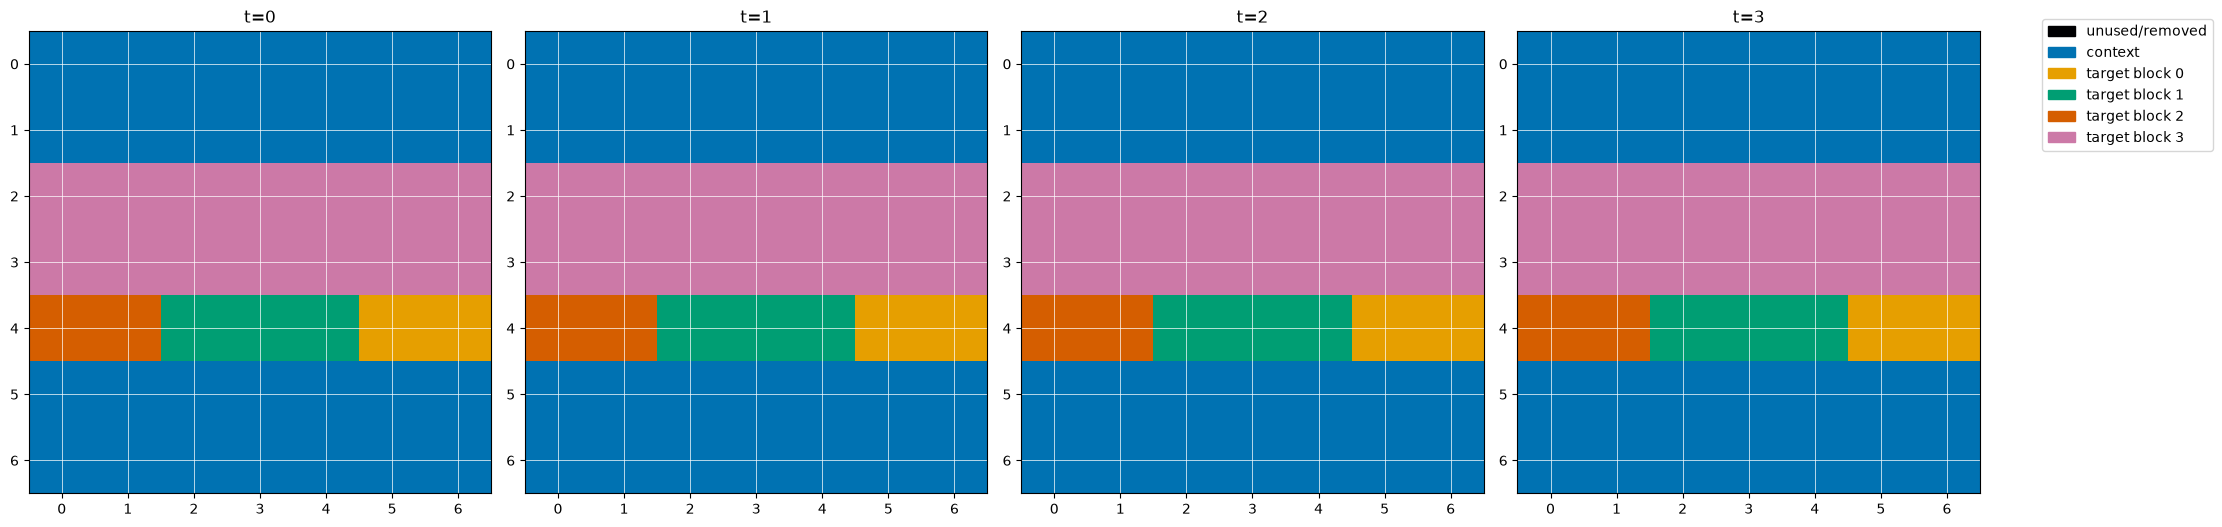

Masking 42.86% of the volume.


In [8]:
Tt = 4
G = 7
# context_idx, target_idx_list = generate_v_jepa_mask(G, T, target_scale=(0.1, 0.15), context_scale=(1, 1))
context_idx, target_idx_list = generate_multi_block_mask(G, Tt, short_range_targets=3, long_range_targets=1,
                                                            short_scale=[.1, .15], short_ar=(.75, 1.5), long_scale=(.2, .35), long_ar=(.3, .9),
                                                         context_scale=(1., 1.), context_ar=(1., 1.))

vis_tube_masks(Tt, G, context_idx, target_idx_list)
plt.tight_layout()
plt.show()

N = Tt * (G ** 2)
mask_p = (N - len(context_idx)) / N
print(f"Masking {mask_p * 100:.2f}% of the volume.")

58369
 pos_embed.shape= torch.Size([196, 864]) 
 mask_token.shape= torch.Size([864])


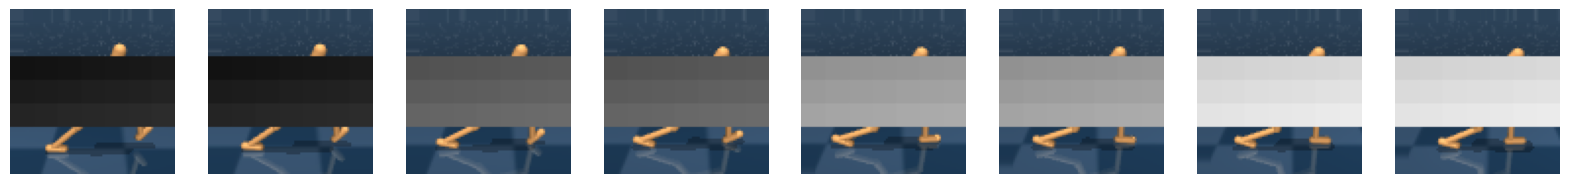

In [ ]:
import random
idx = random.randint(0, len(dataset) - 1)
print(idx)
X, _, _, _, _, _ = dataset[idx]
X_patched = patchify_clip(X.unsqueeze(0), 2, 12)

context_x = jepa_mask(X_patched, context_idx)
mask_token = torch.zeros_like(X_patched[0, 0])
# seeing that tokens are being inflated into the correct positions, the darker a mask token is
pos_embed = torch.arange(N).repeat_interleave(context_x.shape[-1]).reshape(N, -1) / N
pos_embed[context_idx] = 0
print(" pos_embed.shape=", pos_embed.shape, "\n", "mask_token.shape=", mask_token.shape)
full_in, full_idx, _ = build_predictor_input(context_x, context_idx, target_idx_list, pos_embed, mask_token)
full_in_sorted = torch.gather(full_in, dim=1, index=torch.argsort(full_idx).reshape(1, -1, 1).expand(1, -1, full_in.shape[-1]))
pic = unpatchify_clip(full_in_sorted, 8, 2, 84, 12)

draw_clip(pic)

The darkness of the patch indicates the position of the token the patch belongs to along the clip when patchified and flattened into tubelets. It ranges from black (first token) to white (last token) (since we're normalizing by the number of tokens we end up with a range 0/N = 0, ..., N/N = 1). Note the repeating pattern where every 2 patches share the same position, this is due to the tubelets being comprised of two frames.